Import Required Libraries

In [ ]:
#General Health Prediction from CVD Dataset
# Install required libraries (run once in Colab)
!pip install scikit-learn pandas numpy matplotlib seaborn -q

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from scipy.stats import randint, uniform
plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor']   = '#161b22'
plt.rcParams['axes.edgecolor']   = '#30363d'
plt.rcParams['axes.labelcolor']  = '#e6edf3'
plt.rcParams['xtick.color']      = '#8b949e'
plt.rcParams['ytick.color']      = '#8b949e'
plt.rcParams['text.color']       = '#e6edf3'
plt.rcParams['grid.color']       = '#21262d'
plt.rcParams['grid.linestyle']   = '--'
plt.rcParams['font.family']      = 'monospace'
print('All libraries imported successfully!')
print(f'pandas  : {pd.__version__}')
print(f'numpy   : {np.__version__}')
print(f'sklearn : ', end='')
import sklearn; print(sklearn.__version__)

All libraries imported successfully!
pandas  : 2.2.2
numpy   : 2.0.2
sklearn : 1.6.1


Load and Explore Dataset

In [ ]:
# ─── Load Dataset ─────
df = pd.read_csv('/CVD_cleaned.csv')   # adjust path if needed
# Remove trailing empty columns (if any)
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
df.columns = df.columns.str.strip()
print('=' * 55)
print('        CVD DATASET — LOADED SUCCESSFULLY')
print('=' * 55)
print(f'  Shape         : {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'  Memory Usage  : {df.memory_usage(deep=True).sum() / 1e6:.1f} MB')
print(f'  Missing Values: {df.isnull().sum().sum()}')
print('=' * 55)
df.head()

        CVD DATASET — LOADED SUCCESSFULLY
  Shape         : 308,854 rows × 19 columns
  Memory Usage  : 216.3 MB
  Missing Values: 0


,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,Poor,Within the past 2 years,No,No,No,No,No,No,Yes,Female,70-74,150,32.66,14.54,Yes,0,30,16,12
1,Very Good,Within the past year,No,Yes,No,No,No,Yes,No,Female,70-74,165,77.11,28.29,No,0,30,0,4
2,Very Good,Within the past year,Yes,No,No,No,No,Yes,No,Female,60-64,163,88.45,33.47,No,4,12,3,16
3,Poor,Within the past year,Yes,Yes,No,No,No,Yes,No,Male,75-79,180,93.44,28.73,No,0,30,30,8
4,Good,Within the past year,No,No,No,No,No,No,No,Male,80+,191,88.45,24.37,Yes,0,8,4,0


3.1 Dataset Information

3.2 Statistical Summary of Features

In [ ]:
print('\n DATASET INFO:')
df.info()
print('\n STATISTICAL SUMMARY:')
df.describe(include='all').T


 DATASET INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308854 entries, 0 to 308853
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   General_Health                308854 non-null  object 
 1   Checkup                       308854 non-null  object 
 2   Exercise                      308854 non-null  object 
 3   Heart_Disease                 308854 non-null  object 
 4   Skin_Cancer                   308854 non-null  object 
 5   Other_Cancer                  308854 non-null  object 
 6   Depression                    308854 non-null  object 
 7   Diabetes                      308854 non-null  object 
 8   Arthritis                     308854 non-null  object 
 9   Sex                           308854 non-null  object 
 10  Age_Category                  308854 non-null  object 
 11  Height_(cm)                   308854 non-null  int64  
 12  Weight_(kg)                 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
General_Health,308854,5,Very Good,110395,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Checkup,308854,5,Within the past year,239371,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Exercise,308854,2,Yes,239381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Heart_Disease,308854,2,No,283883,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Skin_Cancer,308854,2,No,278860,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Other_Cancer,308854,2,No,278976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Depression,308854,2,No,246953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Diabetes,308854,4,No,259141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Arthritis,308854,2,No,207783,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,308854,2,Female,160196,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Exploratory Data Analysis – Target Variable: General Health

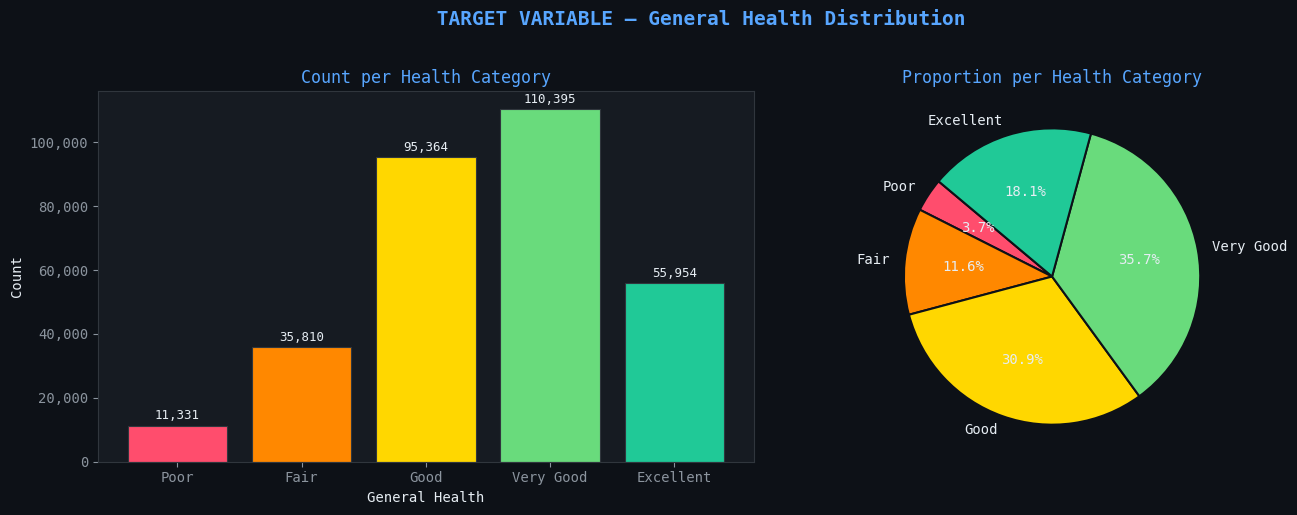

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(' TARGET VARIABLE — General Health Distribution',
             fontsize=14, fontweight='bold', color='#58a6ff', y=1.02)
health_order = ['Poor', 'Fair', 'Good', 'Very Good', 'Excellent']
colors_health = ['#ff4d6d', '#ff8800', '#ffd700', '#69db7c', '#20c997']
counts = df['General_Health'].value_counts().reindex(health_order).fillna(0)
axes[0].bar(health_order, counts.values, color=colors_health, edgecolor='#30363d', linewidth=0.8)
axes[0].set_title('Count per Health Category', color='#58a6ff')
axes[0].set_xlabel('General Health')
axes[0].set_ylabel('Count')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', va='bottom', fontsize=9, color='#e6edf3')
axes[1].pie(counts.values, labels=health_order, colors=colors_health,autopct='%1.1f%%', startangle=140,
        textprops={'color': '#e6edf3', 'fontsize': 10},wedgeprops={'edgecolor': '#0d1117',
        'linewidth': 1.5})
axes[1].set_title('Proportion per Health Category', color='#58a6ff')
plt.tight_layout()
plt.show()

# Exploratory Data Analysis – Categorical Features Distribution

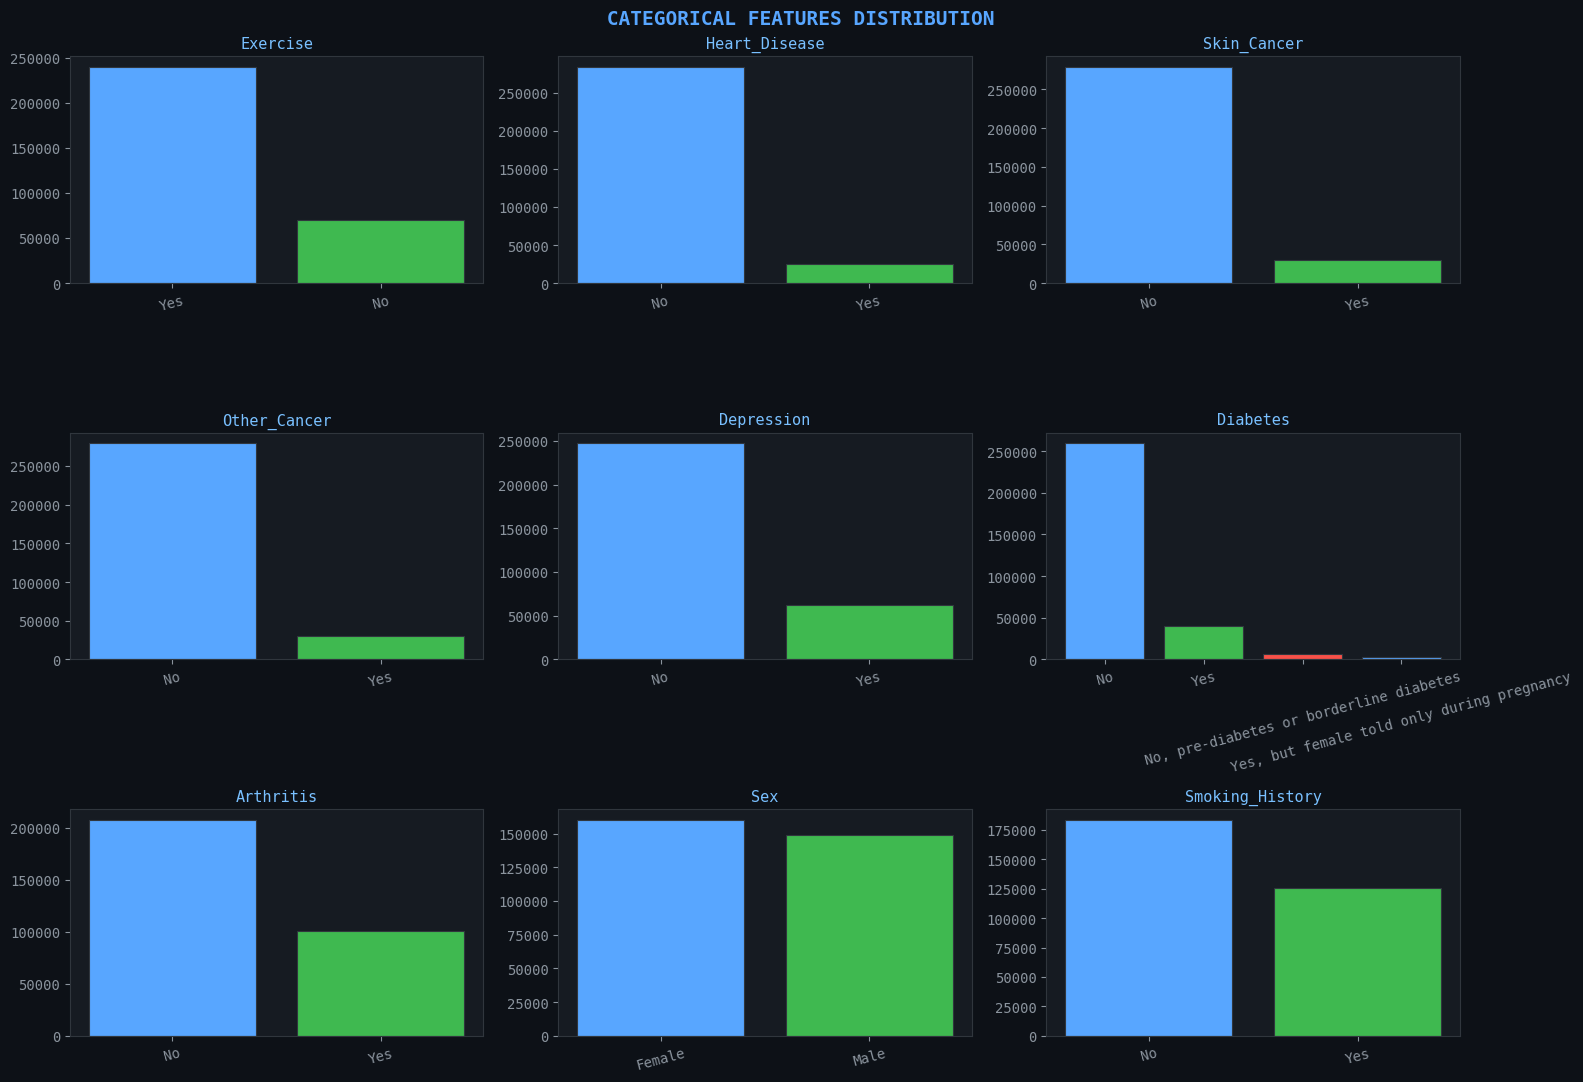

In [ ]:
cat_cols = ['Exercise', 'Heart_Disease', 'Skin_Cancer', 'Other_Cancer',
            'Depression', 'Diabetes', 'Arthritis', 'Sex', 'Smoking_History']
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
fig.suptitle(' CATEGORICAL FEATURES DISTRIBUTION', fontsize=14,fontweight='bold', color='#58a6ff')
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    vc = df[col].value_counts()
    axes[i].bar(vc.index, vc.values,color=['#58a6ff', '#3fb950', '#f85149'][:len(vc)],
                edgecolor='#30363d', linewidth=0.8)
    axes[i].set_title(col, color='#79c0ff', fontsize=11)
    axes[i].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

# Exploratory Data Analysis – Numerical Features Distribution

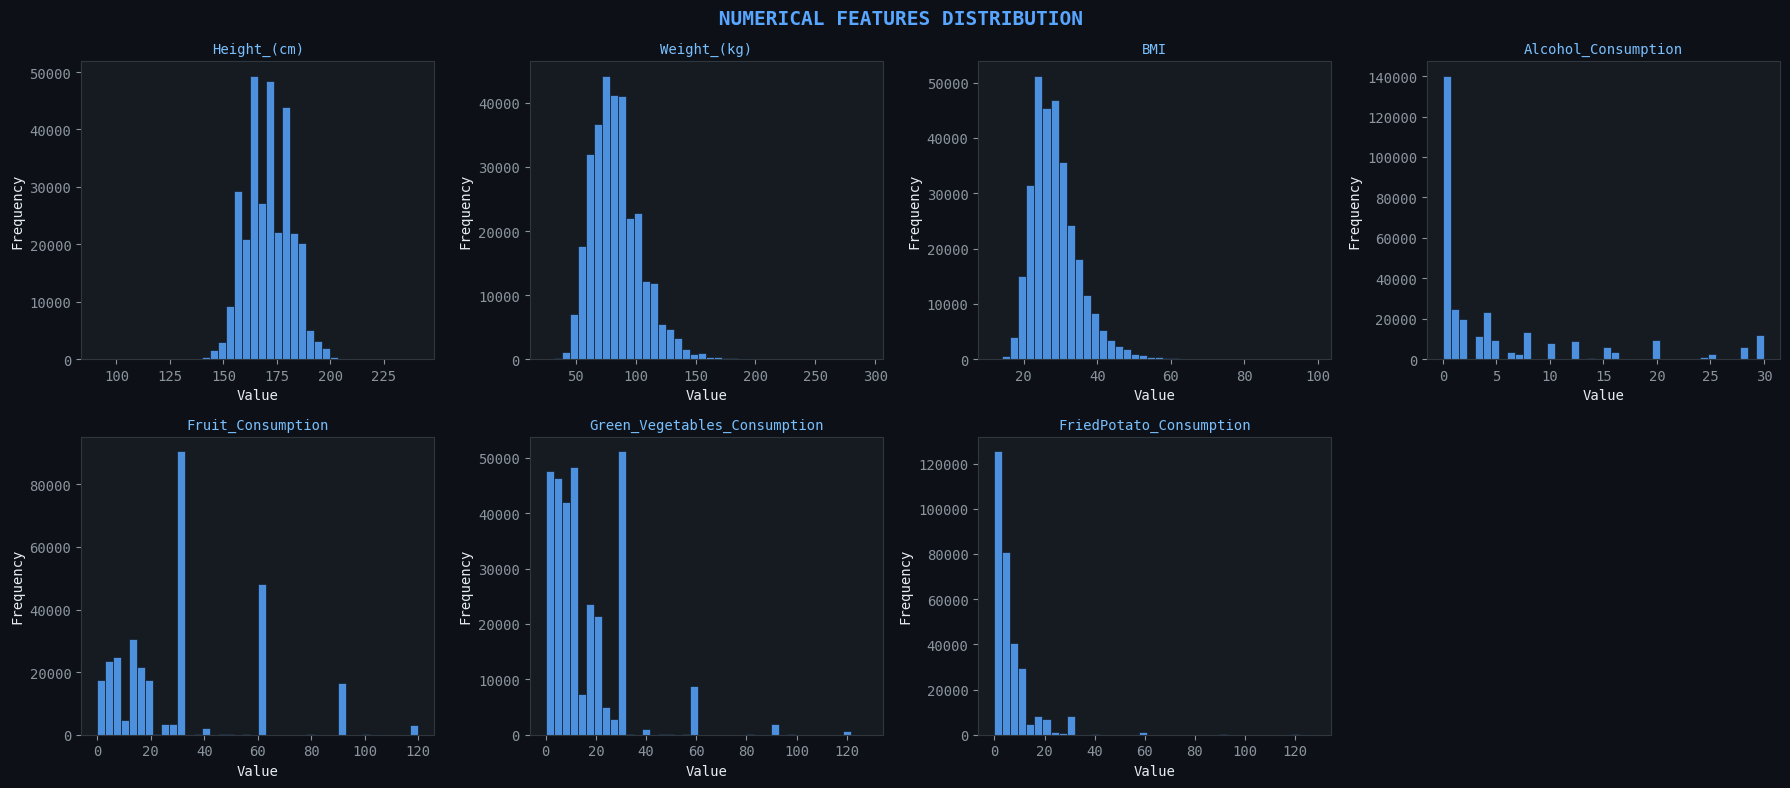

In [ ]:
# ─── Numerical Features Distribution ───────────
num_cols = ['Height_(cm)', 'Weight_(kg)', 'BMI','Alcohol_Consumption', 'Fruit_Consumption',
            'Green_Vegetables_Consumption', 'FriedPotato_Consumption']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle(' NUMERICAL FEATURES DISTRIBUTION', fontsize=14,fontweight='bold', color='#58a6ff')
axes = axes.flatten()
for i, col in enumerate(num_cols):
    axes[i].hist(df[col], bins=40, color='#58a6ff', edgecolor='#0d1117',linewidth=0.5, alpha=0.85)
    axes[i].set_title(col, color='#79c0ff', fontsize=10)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
axes[7].axis('off')
plt.tight_layout()
plt.show()

##   Data Preprocessing

In [ ]:
# ─── Copy dataset ───────────
df_enc = df.copy()
# ─── Label Encoding for all categorical columns ──────
label_encoders = {}
categorical_columns = df_enc.select_dtypes(include=['object']).columns.tolist()
print(' Label Encoding Categorical Features:')
print('-' * 50)
for col in categorical_columns:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col])
    label_encoders[col] = le
    classes = list(le.classes_)
    print(f'  {col:<35} - {classes}')
print('-' * 50)
print(f'\n Encoding complete! {len(categorical_columns)} columns encoded.')
df_enc.head()

 Label Encoding Categorical Features:
--------------------------------------------------
  General_Health                      - ['Excellent', 'Fair', 'Good', 'Poor', 'Very Good']
  Checkup                             - ['5 or more years ago', 'Never', 'Within the past 2 years', 'Within the past 5 years', 'Within the past year']
  Exercise                            - ['No', 'Yes']
  Heart_Disease                       - ['No', 'Yes']
  Skin_Cancer                         - ['No', 'Yes']
  Other_Cancer                        - ['No', 'Yes']
  Depression                          - ['No', 'Yes']
  Diabetes                            - ['No', 'No, pre-diabetes or borderline diabetes', 'Yes', 'Yes, but female told only during pregnancy']
  Arthritis                           - ['No', 'Yes']
  Sex                                 - ['Female', 'Male']
  Age_Category                        - ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,3,2,0,0,0,0,0,0,1,0,10,150,32.66,14.54,1,0,30,16,12
1,4,4,0,1,0,0,0,2,0,0,10,165,77.11,28.29,0,0,30,0,4
2,4,4,1,0,0,0,0,2,0,0,8,163,88.45,33.47,0,4,12,3,16
3,3,4,1,1,0,0,0,2,0,1,11,180,93.44,28.73,0,0,30,30,8
4,2,4,0,0,0,0,0,0,0,1,12,191,88.45,24.37,1,0,8,4,0


# Exploratory Data Analysis – Feature Correlation Heatmap

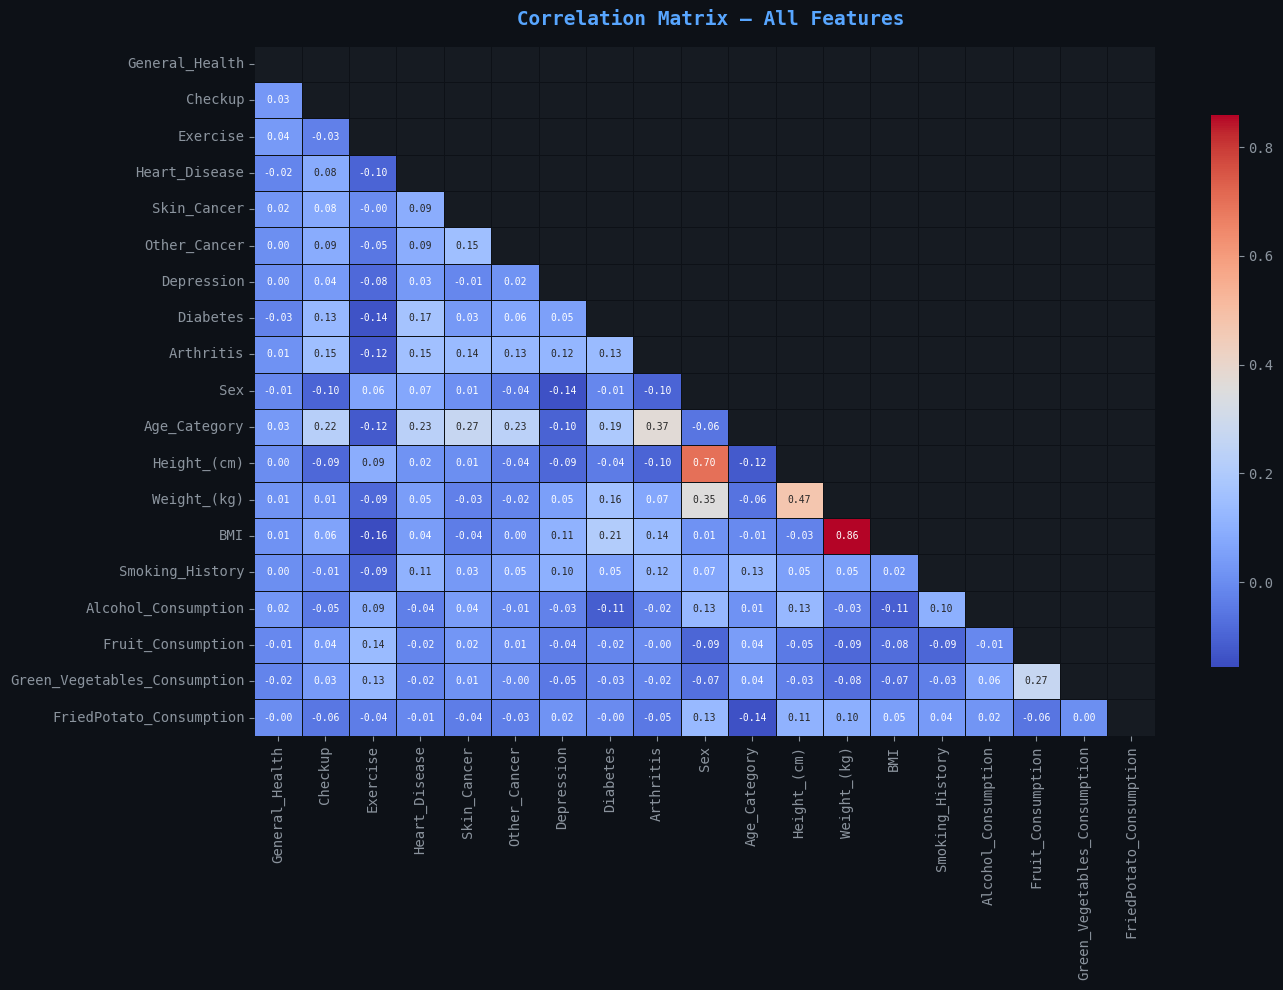

In [ ]:
# ─── Correlation Heatmap ───────────-
plt.figure(figsize=(14, 10))
corr = df_enc.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',cmap='coolwarm', linewidths=0.5,linecolor='#0d1117',
            annot_kws={'size': 7},cbar_kws={'shrink': 0.8})
plt.title(' Correlation Matrix — All Features',fontsize=14, fontweight='bold', color='#58a6ff',
          pad=15)
plt.tight_layout()
plt.show()

##   Train / Test Split (80:20)

In [ ]:
# ─── Define Features and Target ───────────
TARGET = 'General_Health'
X = df_enc.drop(columns=[TARGET])
y = df_enc[TARGET]
# ─── Scale Features (important for SVM and LR) ────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
# ─── 80:20 Stratified Split ───────────
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.20,
    random_state=42,
    stratify=y          # ensures class balance in both splits
)
print('=' * 50)
print('     TRAIN / TEST SPLIT — 80:20 RATIO')
print('=' * 50)
print(f'  Total Samples : {len(df_enc):,}')
print(f'  X_train       : {X_train.shape[0]:,} rows × {X_train.shape[1]} cols')
print(f'  X_test        : {X_test.shape[0]:,} rows × {X_test.shape[1]} cols')
print(f'  y_train       : {y_train.shape[0]:,} labels')
print(f'  y_test        : {y_test.shape[0]:,} labels')
print('=' * 50)
# Class distribution in splits
print('\n Class Distribution in Training Set:')
train_dist = y_train.value_counts().sort_index()
for idx, cnt in train_dist.items():
    label = label_encoders[TARGET].inverse_transform([idx])[0]
    print(f'  Class {idx} ({label:<12}): {cnt:,}  ({100*cnt/len(y_train):.1f}%)')

     TRAIN / TEST SPLIT — 80:20 RATIO
  Total Samples : 308,854
  X_train       : 247,083 rows × 18 cols
  X_test        : 61,771 rows × 18 cols
  y_train       : 247,083 labels
  y_test        : 61,771 labels

 Class Distribution in Training Set:
  Class 0 (Excellent   ): 44,763  (18.1%)
  Class 1 (Fair        ): 28,648  (11.6%)
  Class 2 (Good        ): 76,291  (30.9%)
  Class 3 (Poor        ): 9,065  (3.7%)
  Class 4 (Very Good   ): 88,316  (35.7%)


##   Model Building

In [ ]:
# ─── Helper function for evaluation display ─────────
def evaluate_model(name, model, X_test, y_test, le_target):
    """Evaluate a trained model and display all metrics."""
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    class_names = le_target.classes_
    print('\n' + '='*65)
    print(f'  MODEL: {name}')
    print('='*65)
    print(f'   Accuracy Score : {acc:.4f}  ({acc*100:.2f}%)')
    print('-'*65)
    # Classification Report
    print('\n CLASSIFICATION REPORT:')
    print(classification_report(y_test, y_pred, target_names=class_names))
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=plt.gca(), cmap='Blues', colorbar=True)
    plt.title(f' Confusion Matrix — {name}',
              fontsize=13, fontweight='bold', color='#58a6ff', pad=12)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
    return acc, y_pred
# Store results
results = {}
print(' Evaluation helper function defined!')

 Evaluation helper function defined!


### Support Vector Machine (SVM)

In [ ]:
# ─── FAST SVM TRAINING ────────────
from sklearn.svm import SVC
import time
# Smaller sample for speed
SAMPLE_SIZE = 10000   # reduced from 30000
if len(X_train) > SAMPLE_SIZE:
    from sklearn.utils import resample
    X_train_svm, y_train_svm = resample(
        X_train, y_train,n_samples=SAMPLE_SIZE,random_state=42,stratify=y_train)
    print(f' Using {SAMPLE_SIZE:,} samples for fast SVM training')
else:
    X_train_svm, y_train_svm = X_train, y_train
print(" Training Fast SVM...")
t0 = time.time()
svm_model = SVC(
    kernel='linear',   #MUCH FASTER
    C=1.0,
    random_state=42
)
svm_model.fit(X_train_svm, y_train_svm)
elapsed = time.time() - t0
print(f' SVM training complete! Time: {elapsed:.1f} seconds')

 Using 10,000 samples for fast SVM training
 Training Fast SVM...
 SVM training complete! Time: 11.0 seconds


###  Random Forest Classifier

 Training Random Forest...

 Random Forest training complete! Time: 79.7s

  MODEL: Random Forest Classifier
   Accuracy Score : 0.4066  (40.66%)
-----------------------------------------------------------------

 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   Excellent       0.39      0.25      0.30     11191
        Fair       0.33      0.18      0.23      7162
        Good       0.39      0.46      0.42     19073
        Poor       0.34      0.08      0.14      2266
   Very Good       0.43      0.55      0.48     22079

    accuracy                           0.41     61771
   macro avg       0.38      0.30      0.32     61771
weighted avg       0.40      0.41      0.39     61771



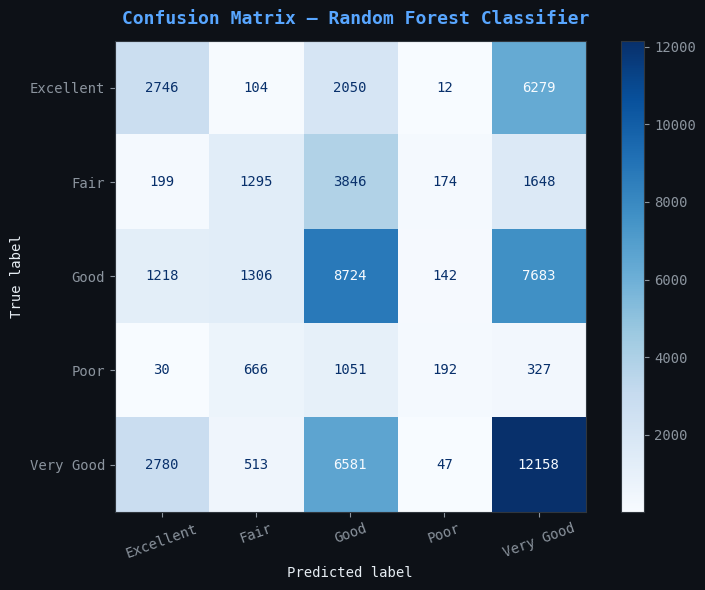

In [ ]:
# ─── Random Forest Training ────────────
print(' Training Random Forest...\n')
t0 = time.time()
rf_model = RandomForestClassifier(n_estimators=100,max_depth=None,min_samples_split=2,
    min_samples_leaf=1,random_state=42,
    n_jobs=-1           # use all CPU cores
)
rf_model.fit(X_train, y_train)
elapsed = time.time() - t0
print(f' Random Forest training complete! Time: {elapsed:.1f}s')
# Evaluate
acc_rf, pred_rf = evaluate_model('Random Forest Classifier',rf_model, X_test, y_test,label_encoders[TARGET])
results['Random Forest'] = acc_rf

# Model Interpretation – Random Forest Feature Importance

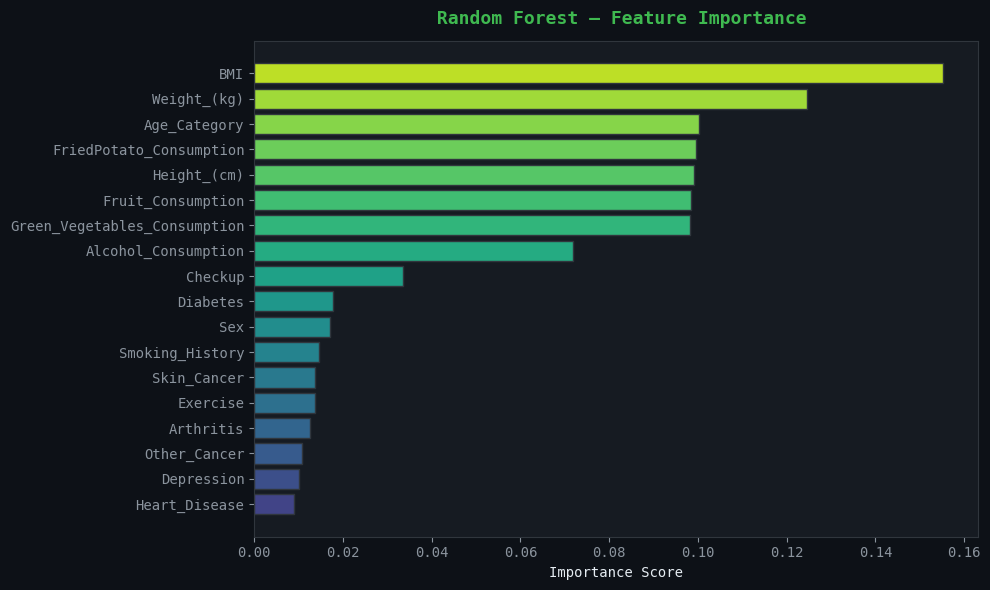


 Top 5 Most Important Features:
  BMI                                 : 0.1552
  Weight_(kg)                         : 0.1245
  Age_Category                        : 0.1002
  FriedPotato_Consumption             : 0.0997
  Height_(cm)                         : 0.0991


In [ ]:
# ─── Feature Importance (Random Forest) ──────────
importances = rf_model.feature_importances_
feat_imp_df = pd.DataFrame({'Feature': X.columns,'Importance': importances}).sort_values('Importance', ascending=False)
plt.figure(figsize=(10, 6))
colors_imp = plt.cm.viridis(np.linspace(0.2, 0.9, len(feat_imp_df)))
plt.barh(feat_imp_df['Feature'], feat_imp_df['Importance'],color=colors_imp[::-1], edgecolor='#30363d')
plt.xlabel('Importance Score')
plt.title(' Random Forest — Feature Importance',fontsize=13, fontweight='bold', color='#3fb950', pad=12)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
print('\n Top 5 Most Important Features:')
for i, row in feat_imp_df.head(5).iterrows():
    print(f'  {row["Feature"]:<35} : {row["Importance"]:.4f}')

### Logistic Regression

 Training Logistic Regression...

 Logistic Regression training complete! Time: 13.0s

  MODEL: Logistic Regression
   Accuracy Score : 0.4227  (42.27%)
-----------------------------------------------------------------

 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   Excellent       0.45      0.13      0.21     11191
        Fair       0.36      0.12      0.19      7162
        Good       0.41      0.43      0.42     19073
        Poor       0.41      0.05      0.09      2266
   Very Good       0.43      0.70      0.53     22079

    accuracy                           0.42     61771
   macro avg       0.41      0.29      0.29     61771
weighted avg       0.42      0.42      0.38     61771



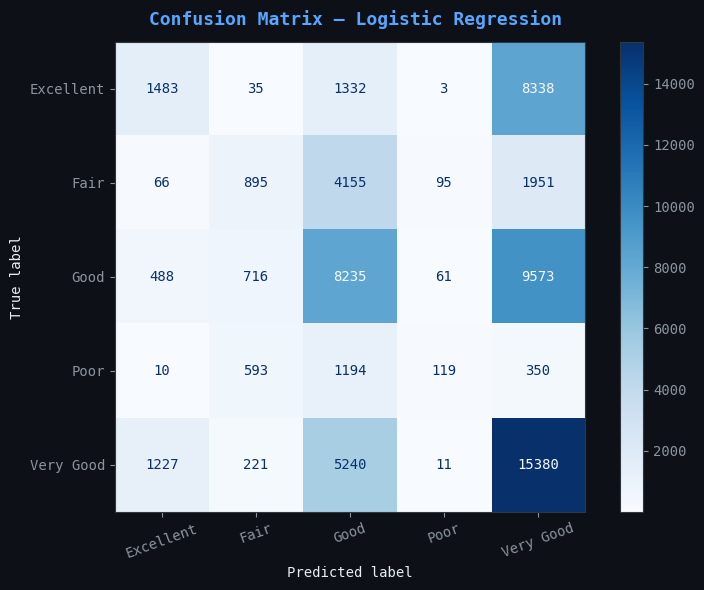

In [ ]:
# ─── Logistic Regression Training ─────────────
print(' Training Logistic Regression...\n')
t0 = time.time()
lr_model = LogisticRegression(multi_class='multinomial',solver='lbfgs',max_iter=1000,C=1.0,random_state=42,
    n_jobs=-1)
lr_model.fit(X_train, y_train)
elapsed = time.time() - t0
print(f' Logistic Regression training complete! Time: {elapsed:.1f}s')
# Evaluate
acc_lr, pred_lr = evaluate_model('Logistic Regression',lr_model, X_test, y_test,label_encoders[TARGET])
results['Logistic Regression'] = acc_lr

##   Accuracy Comparison Bar Chart

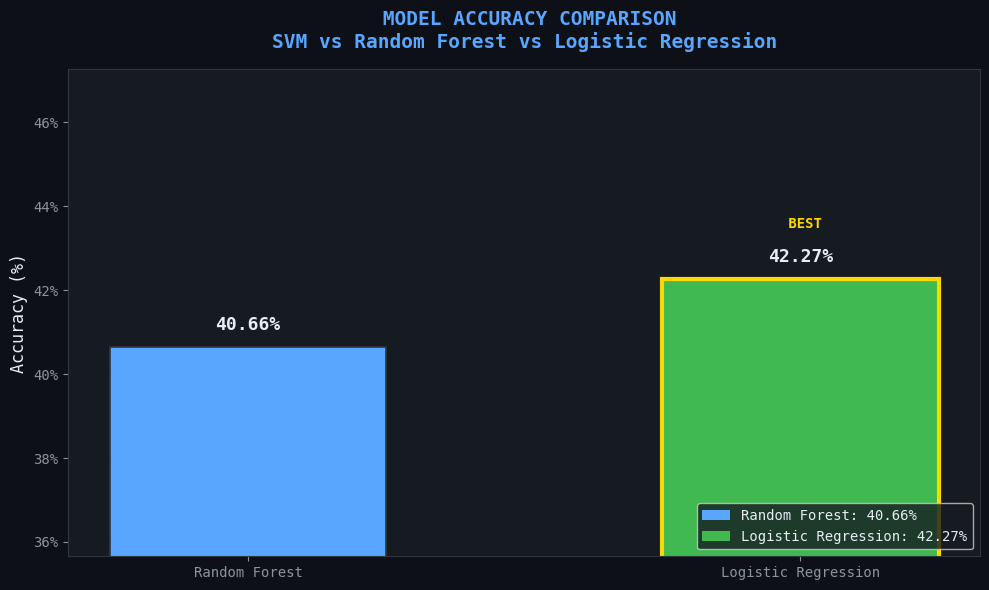


 ACCURACY SUMMARY:
----------------------------------------
  Random Forest            : 40.66%
  Logistic Regression      : 42.27% !BEST

  Best Model → Logistic Regression (42.27%)


In [ ]:
# ─── Accuracy Comparison Bar Chart ──────────
models = list(results.keys())
accuracies = [v * 100 for v in results.values()]
bar_colors = ['#58a6ff', '#3fb950', '#f0883e']
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(models, accuracies, color=bar_colors,
              width=0.5, edgecolor='#30363d', linewidth=1.2)
# Add value labels on bars
for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{acc:.2f}%',
            ha='center', va='bottom',
            fontsize=13, fontweight='bold',
            color='#e6edf3')
# Best model highlight
best_idx = accuracies.index(max(accuracies))
bars[best_idx].set_edgecolor('#ffd700')
bars[best_idx].set_linewidth(3)
ax.text(best_idx, accuracies[best_idx] + 1.2,' BEST', ha='center', fontsize=10,color='#ffd700', fontweight='bold')
ax.set_ylim([min(accuracies) - 5, max(accuracies) + 5])
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title(' MODEL ACCURACY COMPARISON\nSVM vs Random Forest vs Logistic Regression',fontsize=14, fontweight='bold', color='#58a6ff', pad=15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
# Add legend patches
legend_elements = [
    mpatches.Patch(facecolor=bar_colors[i], label=f'{models[i]}: {accuracies[i]:.2f}%')
    for i in range(len(models))
]
ax.legend(handles=legend_elements, loc='lower right',
          framealpha=0.8, fontsize=10)
plt.tight_layout()
plt.savefig('accuracy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('\n ACCURACY SUMMARY:')
print('-' * 40)
for model, acc in zip(models, accuracies):
    star = ' !BEST' if acc == max(accuracies) else ''
    print(f'  {model:<25}: {acc:.2f}%{star}')
print(f'\n  Best Model → {models[best_idx]} ({max(accuracies):.2f}%)')

##   Hyperparameter Tuning (RandomizedSearchCV)

In [ ]:
# ─── Hyperparameter Tuning — Logistic Regression ──────
# (Fastest to tune among the three)
print(' RandomizedSearchCV — Logistic Regression')
print('─' * 55)
param_dist_lr = {
    'C'        : uniform(0.01, 10),           # regularization strength
    'solver'   : ['lbfgs', 'saga'],
    'max_iter' : [500, 1000, 2000],
    'penalty'  : ['l2'],
}
lr_random = RandomizedSearchCV(
    estimator   = LogisticRegression(multi_class='multinomial', random_state=42, n_jobs=-1),
    param_distributions = param_dist_lr,
    n_iter      = 15,
    cv          = StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring     = 'accuracy',
    random_state= 42,
    n_jobs      = -1,
    verbose     = 1
)
lr_random.fit(X_train, y_train)
print(f'\n Best Parameters   : {lr_random.best_params_}')
print(f'   Best CV Accuracy  : {lr_random.best_score_*100:.2f}%')
# Test tuned model
y_pred_lr_tuned = lr_random.best_estimator_.predict(X_test)
acc_lr_tuned = accuracy_score(y_test, y_pred_lr_tuned)
print(f'   Test Accuracy     : {acc_lr_tuned*100:.2f}%')
print(f'   Improvement       : +{(acc_lr_tuned - acc_lr)*100:.2f}%')

 RandomizedSearchCV — Logistic Regression
───────────────────────────────────────────────────────
Fitting 3 folds for each of 15 candidates, totalling 45 fits

 Best Parameters   : {'C': np.float64(1.5701864044243652), 'max_iter': 2000, 'penalty': 'l2', 'solver': 'lbfgs'}
   Best CV Accuracy  : 42.34%
   Test Accuracy     : 42.27%
   Improvement       : +0.00%


# Hyperparameter Tuning – Random Forest using RandomizedSearchCV

In [ ]:
#Hyperparameter Tuning using RandomizedSearchCV – Random Forest
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
print(' Fast RandomizedSearchCV — Random Forest')
print('─' * 55)
# Smaller search space (FASTER)
param_dist_rf = {
    'n_estimators'     : randint(50, 150),   # reduced
    'max_depth'        : [None, 10, 20],
    'min_samples_split': randint(2, 10),
    'min_samples_leaf' : randint(1, 5),
    'max_features'     : ['sqrt', 'log2']
}
rf_random = RandomizedSearchCV(
    estimator   = RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions = param_dist_rf,
    n_iter      = 5,        # reduced from 10
    cv          = 2,        # reduced from 3
    scoring     = 'accuracy',
    random_state= 42,
    n_jobs      = -1,
    verbose     = 1
)
rf_random.fit(X_train, y_train)
print(f'\n Best Parameters   : {rf_random.best_params_}')
print(f'   Best CV Accuracy  : {rf_random.best_score_*100:.2f}%')
y_pred_rf_tuned = rf_random.best_estimator_.predict(X_test)
acc_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)
print(f'   Test Accuracy     : {acc_rf_tuned*100:.2f}%')
print(f'   Improvement       : +{(acc_rf_tuned - acc_rf)*100:.2f}%')

 Fast RandomizedSearchCV — Random Forest
───────────────────────────────────────────────────────
Fitting 2 folds for each of 5 candidates, totalling 10 fits

 Best Parameters   : {'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 9, 'n_estimators': 109}
   Best CV Accuracy  : 42.64%
   Test Accuracy     : 42.77%
   Improvement       : +2.11%


# Model Evaluation – Accuracy Comparison Before and After Hyperparameter Tuning

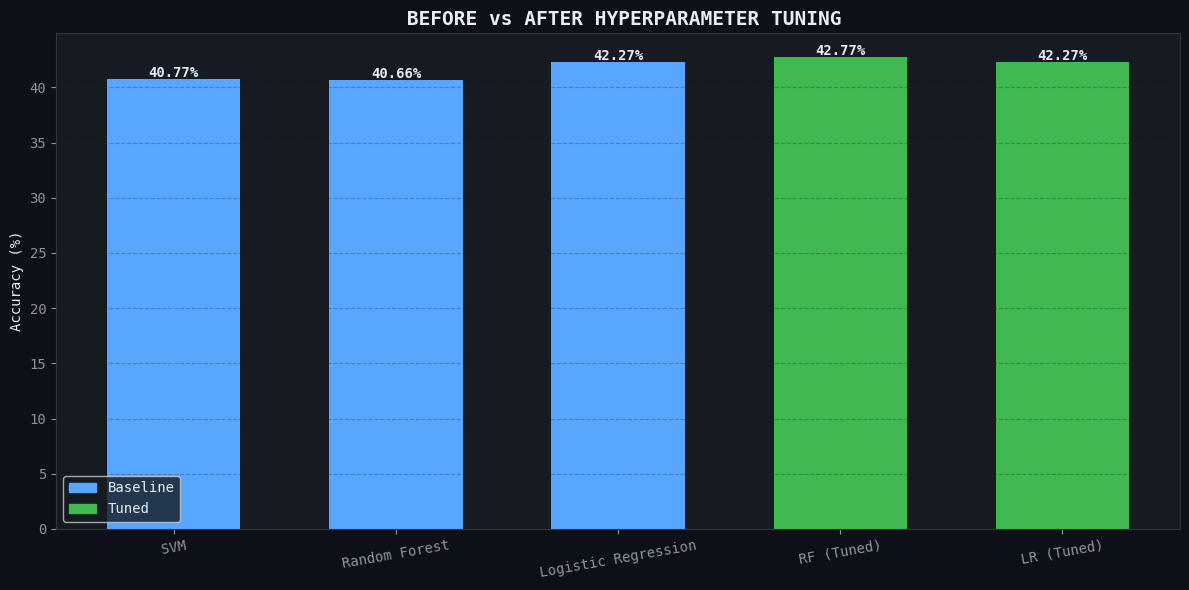

In [ ]:
# ─── Tuning Results Comparison ─────────────────
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.metrics import accuracy_score
# ===============================
# RE-CALCULATE ACCURACIES SAFELY
# ===============================
acc_svm = accuracy_score(y_test, svm_model.predict(X_test))
acc_rf = accuracy_score(y_test, rf_model.predict(X_test))
acc_lr = accuracy_score(y_test, lr_model.predict(X_test))
acc_rf_tuned = accuracy_score(y_test, rf_random.best_estimator_.predict(X_test))
# If Logistic Regression tuning exists
try:
    acc_lr_tuned = accuracy_score(y_test, lr_random.best_estimator_.predict(X_test))
    include_lr_tuned = True
except:
    include_lr_tuned = False
# ===============================
# CREATE DATAFRAME
# ===============================
if include_lr_tuned:
    tuning_data = {
        'Model': ['SVM', 'Random Forest', 'Logistic Regression',
                  'RF (Tuned)', 'LR (Tuned)'],
        'Accuracy (%)': [acc_svm*100, acc_rf*100, acc_lr*100,
                         acc_rf_tuned*100, acc_lr_tuned*100],
        'Type': ['Baseline', 'Baseline', 'Baseline', 'Tuned', 'Tuned']
    }
else:
    tuning_data = {
        'Model': ['SVM', 'Random Forest', 'Logistic Regression',
                  'RF (Tuned)'],
        'Accuracy (%)': [acc_svm*100, acc_rf*100, acc_lr*100,
                         acc_rf_tuned*100],
        'Type': ['Baseline', 'Baseline', 'Baseline', 'Tuned']
    }
tuning_df = pd.DataFrame(tuning_data)

# PLOT GRAPH

colors_type = {'Baseline': '#58a6ff', 'Tuned': '#3fb950'}
bar_c = [colors_type[t] for t in tuning_df['Type']]
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(tuning_df['Model'], tuning_df['Accuracy (%)'],
              color=bar_c, width=0.6)
for bar, acc in zip(bars, tuning_df['Accuracy (%)']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.2,
            f'{acc:.2f}%',
            ha='center', fontsize=10, fontweight='bold')
ax.set_ylabel('Accuracy (%)')
ax.set_title(' BEFORE vs AFTER HYPERPARAMETER TUNING',
             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
legend_patches = [
    mpatches.Patch(color='#58a6ff', label='Baseline'),
    mpatches.Patch(color='#3fb950', label='Tuned')
]
ax.legend(handles=legend_patches)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

##   Single Input Prediction — AI System Demo

In [ ]:
# ─── Single Input Prediction Function ───────────
def predict_health_status(input_dict, model=None, use_best=True):
    """
    Predict General Health Status from a single patient record.

    Parameters:
        input_dict (dict): Patient feature values
        model: Sklearn model (optional, defaults to best tuned model)
        use_best (bool): If True, uses best tuned model

    Returns:
        str: Predicted health status
    """
    # Choose model
    if model is None:
        best_accs = {
            'SVM'               : acc_svm,
            'Random Forest'     : acc_rf_tuned,
            'Logistic Regression': acc_lr_tuned
        }
        best_name = max(best_accs, key=best_accs.get)
        if best_name == 'SVM':
            chosen_model = svm_model
        elif best_name == 'Random Forest':
            chosen_model = rf_random.best_estimator_
        else:
            chosen_model = lr_random.best_estimator_
    else:
        chosen_model = model
        best_name = 'Custom'

    # Encode categorical features in input
    input_enc = {}
    for col, val in input_dict.items():
        if col in label_encoders:
            try:
                input_enc[col] = label_encoders[col].transform([val])[0]
            except ValueError:
                print(f'  Unknown value "{val}" for column "{col}". Using 0.')
                input_enc[col] = 0
        else:
            input_enc[col] = val

    # Create DataFrame with same feature order as training
    input_df = pd.DataFrame([input_enc])[X.columns]
    # Scale
    input_scaled = scaler.transform(input_df)
    # Predict
    prediction_encoded = chosen_model.predict(input_scaled)[0]
    prediction_label   = label_encoders[TARGET].inverse_transform([prediction_encoded])[0]
    # Probability (if supported)
    try:
        proba = chosen_model.predict_proba(input_scaled)[0]
        conf  = max(proba) * 100
    except Exception:
        proba = None
        conf  = None
    return prediction_label, conf, best_name, proba
print(' AI Prediction function ready!')

 AI Prediction function ready!


# AI Prediction Demo – Test with a Sample Patient from the Dataset

In [ ]:
# ─── Test the AI System with a sample from the dataset ────────
# We take row index 5 as our sample patient
sample_row = df.iloc[5].drop('General_Health')
actual_health = df.iloc[5]['General_Health']
print('=' * 60)
print('      CardioVision AI — PATIENT HEALTH PREDICTOR')
print('=' * 60)
print('\n PATIENT PROFILE (Input Data):')
print('-' * 40)
for k, v in sample_row.items():
    print(f'  {k:<38}: {v}')
# Make prediction
pred_label, confidence, model_used, probabilities = predict_health_status(
    sample_row.to_dict()
)
# Emoji map
health_emoji = {
    'Poor': '🔴','Fair': '🟠','Good': '🟡','Very Good': '🟢','Excellent': '✅'}
print('\n' + '=' * 60)
print('   PREDICTION RESULT')
print('=' * 60)
print(f'  Model Used          : {model_used}')
print(f'  Actual Health       : {actual_health}')
print(f'  Predicted Health    : {health_emoji.get(pred_label, "")} {pred_label}')
if confidence:
    print(f'  Confidence          : {confidence:.1f}%')
print(f'  Correct Prediction  : {"✅ YES" if pred_label == actual_health else "❌ NO"}')
print('=' * 60)
# Show all class probabilities
if probabilities is not None:
    print('\n PROBABILITY DISTRIBUTION:')
    class_names = label_encoders[TARGET].classes_
    for cls, prob in sorted(zip(class_names, probabilities), key=lambda x: -x[1]):
        bar_fill = '█' * int(prob * 30)
        bar_empty = '░' * (30 - int(prob * 30))
        print(f'  {cls:<12}: {bar_fill}{bar_empty} {prob*100:5.1f}%')

      CardioVision AI — PATIENT HEALTH PREDICTOR

 PATIENT PROFILE (Input Data):
----------------------------------------
  Checkup                               : Within the past year
  Exercise                              : No
  Heart_Disease                         : No
  Skin_Cancer                           : No
  Other_Cancer                          : No
  Depression                            : Yes
  Diabetes                              : No
  Arthritis                             : Yes
  Sex                                   : Male
  Age_Category                          : 60-64
  Height_(cm)                           : 183
  Weight_(kg)                           : 154.22
  BMI                                   : 46.11
  Smoking_History                       : No
  Alcohol_Consumption                   : 0
  Fruit_Consumption                     : 12
  Green_Vegetables_Consumption          : 12
  FriedPotato_Consumption               : 12

   PREDICTION RESULT
  Model Used  

# Interactive AI Prediction – Custom Patient Input

In [ ]:
# ─── Interactive Custom Prediction ──────────────
# CUSTOMIZE THIS SECTION to test with your own values!
custom_patient = {
    'Checkup'                    : 'Within the past year',
    'Exercise'                   : 'Yes',
    'Heart_Disease'              : 'No',
    'Skin_Cancer'                : 'No',
    'Other_Cancer'               : 'No',
    'Depression'                 : 'No',
    'Diabetes'                   : 'No',
    'Arthritis'                  : 'No',
    'Sex'                        : 'Male',
    'Age_Category'               : '25-29',
    'Height_(cm)'                : 175,
    'Weight_(kg)'                : 70,
    'BMI'                        : 22.86,
    'Smoking_History'            : 'No',
    'Alcohol_Consumption'        : 2,
    'Fruit_Consumption'          : 20,
    'Green_Vegetables_Consumption': 15,
    'FriedPotato_Consumption'    : 5
}
print('=' * 60)
print('   CUSTOM PATIENT PREDICTION')
print('=' * 60)
pred_label2, confidence2, model_used2, probabilities2 = predict_health_status(custom_patient)
print('\n Input Values:')
for k, v in custom_patient.items():
    print(f'  {k:<38}: {v}')
print(f'\n Predicted General Health : {health_emoji.get(pred_label2, "")} {pred_label2}')
if confidence2:
    print(f'   Confidence Score        : {confidence2:.1f}%')
if probabilities2 is not None:
    class_names = label_encoders[TARGET].classes_
    print('\n Class Probabilities:')
    for cls, prob in sorted(zip(class_names, probabilities2), key=lambda x: -x[1]):
        bar_fill  = '█' * int(prob * 30)
        bar_empty = '░' * (30 - int(prob * 30))
        marker = ' ← PREDICTED' if cls == pred_label2 else ''
        print(f'  {cls:<12}: {bar_fill}{bar_empty} {prob*100:5.1f}%{marker}')

   CUSTOM PATIENT PREDICTION

 Input Values:
  Checkup                               : Within the past year
  Exercise                              : Yes
  Heart_Disease                         : No
  Skin_Cancer                           : No
  Other_Cancer                          : No
  Depression                            : No
  Diabetes                              : No
  Arthritis                             : No
  Sex                                   : Male
  Age_Category                          : 25-29
  Height_(cm)                           : 175
  Weight_(kg)                           : 70
  BMI                                   : 22.86
  Smoking_History                       : No
  Alcohol_Consumption                   : 2
  Fruit_Consumption                     : 20
  Green_Vegetables_Consumption          : 15
  FriedPotato_Consumption               : 5

 Predicted General Health : 🟢 Very Good
   Confidence Score        : 44.0%

 Class Probabilities:
  Very Good   : ████

##  Final Summary Report

In [ ]:
# ─── Final Summary ────────────────────
print('\n')
print('█'*65)
print('    CVD GENERAL HEALTH PREDICTION — FINAL SUMMARY REPORT')
print('█'*65)
print(f'  Dataset         : CVD_cleaned.csv  ({len(df):,} records)')
print(f'  Features Used   : {X.shape[1]} (after preprocessing)')
print(f'  Train Set Size  : {len(X_train):,} ({80}%)')
print(f'  Test Set Size   : {len(X_test):,}  ({20}%)')
print()
print('  ─── MODEL PERFORMANCE (on X_test) ─────────────────────')
print(f'  {'Model':<30} {'Baseline':>10}  {'After Tuning':>12}')
print(f'  {'─'*30} {'─'*10}  {'─'*12}')
print(f'  {'SVM':<30} {acc_svm*100:>9.2f}%  {'N/A':>12}')
print(f'  {'Random Forest':<30} {acc_rf*100:>9.2f}%  {acc_rf_tuned*100:>11.2f}%')
print(f'  {'Logistic Regression':<30} {acc_lr*100:>9.2f}%  {acc_lr_tuned*100:>11.2f}%')
print()
all_accs = {
    'SVM': acc_svm,'Random Forest (Tuned)': acc_rf_tuned,'Logistic Regression (Tuned)': acc_lr_tuned
}
best_overall = max(all_accs, key=all_accs.get)
print(f'   Best Model   : {best_overall} ({all_accs[best_overall]*100:.2f}%)')
print()
print('  ─── PREDICTION DEMO ─────────────────────────────────────')
print(f'  Input           : Patient profile (18 features)')
print(f'  Predicted Health: {pred_label2}')
if confidence2:
    print(f'  Confidence      : {confidence2:.1f}%')
print()
print('█'*65)
print('      Project Completed Successfully!')
print('     Data Science Internship — CVD Health Prediction')
print('█'*65)



█████████████████████████████████████████████████████████████████
    CVD GENERAL HEALTH PREDICTION — FINAL SUMMARY REPORT
█████████████████████████████████████████████████████████████████
  Dataset         : CVD_cleaned.csv  (308,854 records)
  Features Used   : 18 (after preprocessing)
  Train Set Size  : 247,083 (80%)
  Test Set Size   : 61,771  (20%)

  ─── MODEL PERFORMANCE (on X_test) ─────────────────────
  Model                            Baseline  After Tuning
  ────────────────────────────── ──────────  ────────────
  SVM                                40.77%           N/A
  Random Forest                      40.66%        42.77%
  Logistic Regression                42.27%        42.27%

   Best Model   : Random Forest (Tuned) (42.77%)

  ─── PREDICTION DEMO ─────────────────────────────────────
  Input           : Patient profile (18 features)
  Predicted Health: Very Good
  Confidence      : 44.0%

█████████████████████████████████████████████████████████████████
      Pr